In [1]:
# Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import pandas as pd

# Load historical air passengers data
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url)

# Display first 5 rows
print("First 5 rows of the dataset:")
display(df.head())

# Dataset information
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

First 5 rows of the dataset:


,Month,Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


Dataset shape: (144, 2)
Column names: ['Month', 'Passengers']


In [3]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check data types
print("\nData types:")
print(df.dtypes)

Missing values:
Month         0
Passengers    0
dtype: int64
Duplicate rows: 0

Data types:
Month         object
Passengers     int64
dtype: object


In [4]:
# Convert Month column to date format
df["Month"] = pd.to_datetime(df["Month"])

# Extract year and month
df["Year"] = df["Month"].dt.year
df["Month_Number"] = df["Month"].dt.month

# Check the processed data
print("Preprocessed Dataset:")
display(df.head(10))

# Check missing values again
print("\nMissing Values:")
print(df.isnull().sum())

Preprocessed Dataset:


,Month,Passengers,Year,Month_Number
0,1949-01-01,112,1949,1
1,1949-02-01,118,1949,2
2,1949-03-01,132,1949,3
3,1949-04-01,129,1949,4
4,1949-05-01,121,1949,5
5,1949-06-01,135,1949,6
6,1949-07-01,148,1949,7
7,1949-08-01,148,1949,8
8,1949-09-01,136,1949,9
9,1949-10-01,119,1949,10



Missing Values:
Month           0
Passengers      0
Year            0
Month_Number    0
dtype: int64


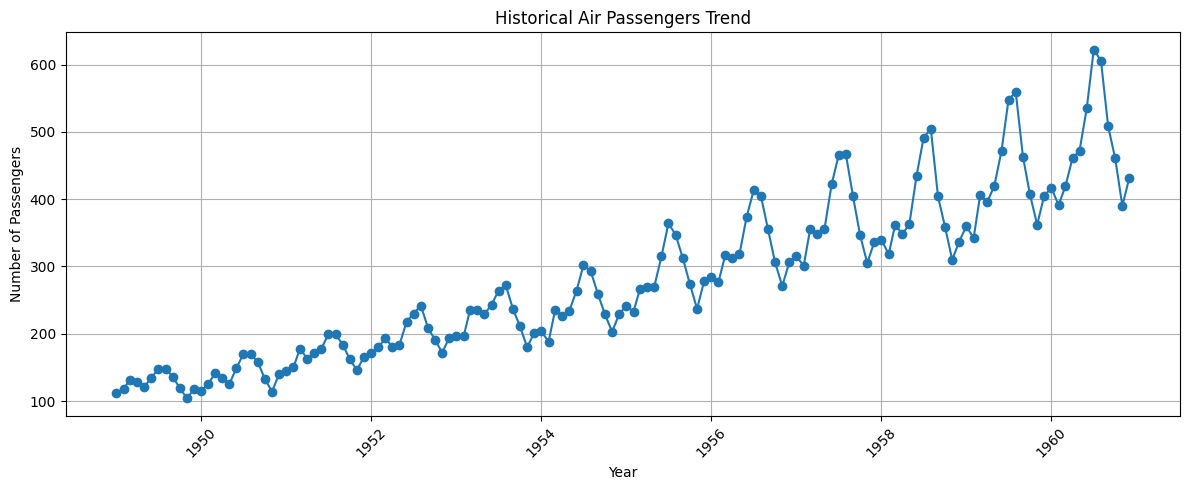

In [5]:
plt.figure(figsize=(12, 5))

plt.plot(df["Month"], df["Passengers"], marker="o")

plt.title("Historical Air Passengers Trend")
plt.xlabel("Year")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [6]:
# Select input features and target
X = df[["Year", "Month_Number"]]
y = df["Passengers"]

# Split historical data:
# First 80% for training, last 20% for testing
split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

print("Model training completed successfully!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Model training completed successfully!
Training records: 115
Testing records: 29


In [7]:
# Predict passenger counts for test data
y_pred = model.predict(X_test)

# Evaluate model performance
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared Score: {r2:.4f}")

Model Evaluation Results
------------------------
Mean Absolute Error (MAE): 55.92
Root Mean Squared Error (RMSE): 73.82
R-squared Score: 0.1074


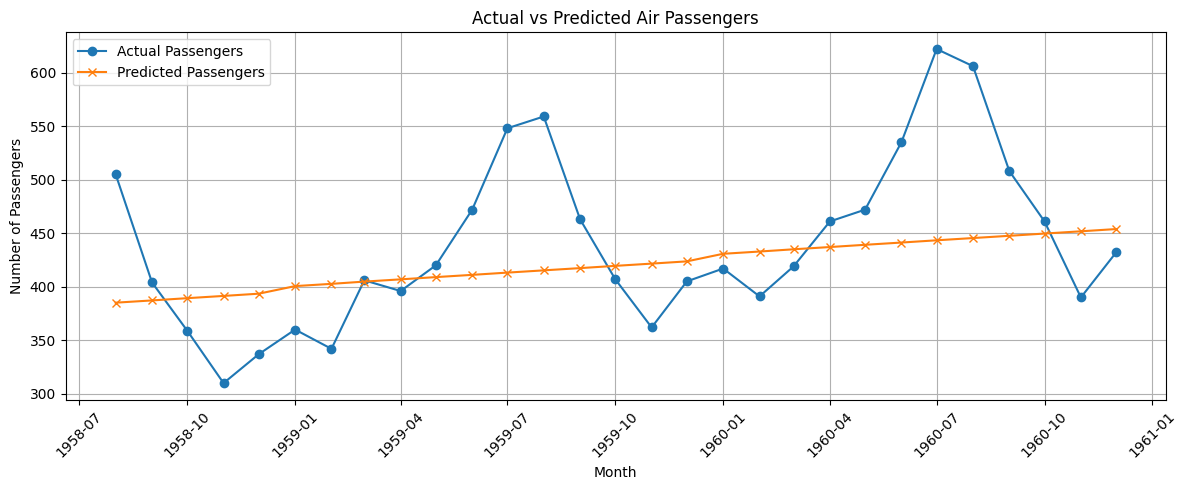

In [8]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["Month"].iloc[split_index:],
    y_test,
    label="Actual Passengers",
    marker="o"
)

plt.plot(
    df["Month"].iloc[split_index:],
    y_pred,
    label="Predicted Passengers",
    marker="x"
)

plt.title("Actual vs Predicted Air Passengers")
plt.xlabel("Month")
plt.ylabel("Number of Passengers")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [9]:
# Generate the next 12 months
last_month = df["Month"].max()

future_dates = pd.date_range(
    start=last_month + pd.offsets.MonthBegin(1),
    periods=12,
    freq="MS"
)

# Prepare future input features
future_df = pd.DataFrame({
    "Year": future_dates.year,
    "Month_Number": future_dates.month
})

# Predict future passenger counts
future_predictions = model.predict(future_df[["Year", "Month_Number"]])

future_df["Predicted_Passengers"] = np.round(
    future_predictions
).astype(int)

print("Future Passenger Forecast")
display(future_df)

Future Passenger Forecast


,Year,Month_Number,Predicted_Passengers
0,1961,1,461
1,1961,2,463
2,1961,3,465
3,1961,4,467
4,1961,5,469
5,1961,6,471
6,1961,7,474
7,1961,8,476
8,1961,9,478
9,1961,10,480


In [10]:
# Save model evaluation results
evaluation = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2 Score"],
    "Value": [mae, rmse, r2]
})

evaluation.to_csv("Model_Evaluation_Results.csv", index=False)

# Save future predictions
future_df.to_csv("Future_Passenger_Forecast.csv", index=False)

# Save actual vs predicted comparison
comparison = pd.DataFrame({
    "Month": df["Month"].iloc[split_index:].values,
    "Actual_Passengers": y_test.values,
    "Predicted_Passengers": np.round(y_pred, 2)
})

comparison.to_csv("Actual_vs_Predicted.csv", index=False)

print("All result files saved successfully!")

All result files saved successfully!


In [11]:
from google.colab import files

files.download("Model_Evaluation_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
files.download("Future_Passenger_Forecast.csv")
files.download("Actual_vs_Predicted.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>